In [1]:
import jax
import jax.numpy as jnp
import diffrax
import optimistix

jax.config.update("jax_enable_x64", True)

# ── Physical constants ────────────────────────────────────────────────────────
MP2     = 1.0
OMEGA_R = 8.24e-5       # radiation density parameter (fixed, from DESI DR2)
H_NORM  = 0.67          # dimensionless Hubble for ODE normalisation
C_KMS   = 299792.458    # speed of light [km/s]

In [2]:
def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

In [96]:
OMEGA_R = omega_r(H_NORM)

In [97]:
# ── Validity check (to be used in logprior) ───────────────────────────────────
def constraints_satisfied(stigma, cpr):
    """Returns (c1, c2) where both must be >0 for valid parameters."""
    c1 = stigma - cpr**2                                          # > 0
    c2 = cpr**2 - stigma*(5 + 4*stigma*(-2 + cpr**2))            # > 0
    return c1, c2


In [98]:
def small_jax(cpr, omega_m, stigma, mups2, omr=OMEGA_R, h=H_NORM):
    """Compute the initial conformal time tauini (same logic as small() in equations_double.py)."""
    # Denominator in sqrt argument (negative for valid params by constraint 2)
    denom_sqrt = -cpr**2 + 5*stigma + 4*(-2 + cpr**2)*stigma**2

    sqrt_arg = omr * stigma * (-cpr**2 + stigma) * (-mups2) / denom_sqrt
    sqrt_val = jnp.sqrt(jnp.maximum(sqrt_arg, 0.0))

    big_poly_num = (
        cpr * (
            stigma**3*(5 + stigma)*(-1 + 2*stigma)
            + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + 3*(-1 + stigma)*stigma)
            + 3*cpr**2*stigma**2*(8 + stigma*(-17 + 3*stigma))
            - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + stigma*(14 + stigma)))
        ) * sqrt_val
    )

    big_poly_den = (
        h * (
            2*cpr**2*(-4 + stigma)*(-1 + stigma)*stigma**3
            + stigma**4 - 2*stigma**5
            + 2*cpr**4*stigma**2*(2 + stigma)*(-3 + 4*stigma)
            + 2*cpr**6*stigma*(2 + stigma - 7*stigma**2)
            + cpr**8*(-1 + 4*stigma**2)
        ) * omega_m
    )

    return jnp.abs(big_poly_num) / (jnp.abs(big_poly_den) * 250000.0)


In [99]:
def aseries_jax(tau, cpr, omega_m, h, a0, stigma, mups2, omr):
    """Series expansion of a(tau) to O(tau^3)."""
    # Common sub-expressions
    s = stigma; c = cpr; m = mups2; r = omr
    D1 = (c**2 - 5*s + 4*(2 - c**2)*s**2)                           # > 0 for valid params
    D2 = (s**3*(5+s)*(-1+2*s) + c**6*(-1+2*s)*(1+2*s)*(-2+3*(-1+s)*s)
          + 3*c**2*s**2*(8+s*(-17+3*s)) - c**4*s*(11+s+2*s**2*(-30+s*(14+s))))
    D3 = (s**3*(16-s*(23+20*s)) + c**2*s**2*(-57+2*s*(41-7*(-5+s)*s))
          - 3*c**6*(3+2*s*(1+s)*(1+4*(-2+s)*s))
          + c**4*s*(36+s*(3+2*s*(-88+s*(23+5*s)))))

    t1 = (200*h*r**(1/2)*s**(1/2)*(-c**2+s)**(1/2)*tau) / (a0*c*m**(1/2)*D1**(1/2))

    t2_num = (2*c**2*(-4+s)*(-1+s)*s**3 + s**4 - 2*s**5
              + 2*c**4*s**2*(2+s)*(-3+4*s) + 2*c**6*s*(2+s-7*s**2)
              + c**8*(-1+4*s**2))
    t2 = -(5000*h**2*t2_num*tau**2*omega_m) / (a0*c**2*m*D2)

    t3_num = (-12*c**18*(-1+s)*(-1+4*s**2)**3
              + s**8*(38+s*(-287+4*s*(103+(17-24*s)*s)))
              + c**16*(1-4*s**2)**2*(18+s*(111+2*s*(-107+s*(-59+109*s))))
              + 2*c**2*s**7*(99+s*(375+s*(-1187+s*(37+4*(43-9*s)*s))))
              + 2*c**4*s**6*(-1632+s*(4497+s*(-4915+s*(5505+s*(-1215+14*s*(-43+18*s))))))
              - 2*c**14*s*(-1+2*s)*(1+2*s)*(-93+s*(-125+s*(1081+s*(475+2*s*(-1547+2*s*(421+63*s))))))
              + 2*c**6*s**5*(1889+s*(221+s*(-14701+s*(19921+2*s*(-7251+2*s*(711+(188-51*s)*s))))))
              + 2*c**8*s**4*(-648+s*(-4704+s*(10957+s*(13373+s*(-33001+4*s*(5742+s*(-889+s*(-175+9*s))))))))
              + 2*c**10*s**3*(-399+s*(3727+s*(1965+s*(-24061+4*s*(2735+s*(5248+s*(-5021+s*(699+86*s))))))))
              - 2*c**12*s**2*(-340+s*(569+s*(5253+s*(-7943+s*(-14915+2*s*(11863+2*s*(-164+s*(-2183+287*s)))))))))
    t3 = (62500*h**3*s**(1/2)*(-c**2+s)**(3/2)*(c**2-s*(5+4*(-2+c**2)*s))**(1/2)
          * t3_num * tau**3 * omega_m**2) / (a0*c**3*m**(3/2)*r**(1/2)*D2**2*D3)

    return t1 + t2 + t3


def cpseries_jax(tau, cpr, omega_m, h, a0, stigma, mups2, omr):
    """Series expansion of cp(tau) to O(tau^2)."""
    s = stigma; c = cpr; m = mups2; r = omr
    D2 = (s**3*(5+s)*(-1+2*s) + c**6*(-1+2*s)*(1+2*s)*(-2+3*(-1+s)*s)
          + 3*c**2*s**2*(8+s*(-17+3*s)) - c**4*s*(11+s+2*s**2*(-30+s*(14+s))))
    D3 = (s**3*(16-s*(23+20*s)) + c**2*s**2*(-57+2*s*(41-7*(-5+s)*s))
          - 3*c**6*(3+2*s*(1+s)*(1+4*(-2+s)*s))
          + c**4*s*(36+s*(3+2*s*(-88+s*(23+5*s)))))

    t1_num = ((-c**2+s)**(3/2)*(c**2-s*(5+4*(-2+c**2)*s))**(1/2)
              * ((5-2*s)*s**2 + 2*c**2*s*(1+(-5+s)*s) + c**4*(-1+4*s**2)))
    t1 = (25*h*t1_num*tau*omega_m) / (m**(1/2)*r**(1/2)*s**(1/2)*D2)

    t2_num_poly = (6*c**16*(-1+4*s**2)**3
                   + s**8*(-1+2*s)*(-50+s*(-61+2*s*(-11+8*s)))
                   + c**14*s*(1-4*s**2)**2*(48+s*(-35+6*s*(-19+(-3+s)*s)))
                   + c**2*s**7*(-922+s*(2351+2*s*(-597+s*(43+4*(55-13*s)*s))))
                   - c**12*s**2*(-1+2*s)*(1+2*s)*(-214+s*(323+2*s*(596+s*(-626+s*(-439+16*s*(-3+2*s))))))
                   + c**4*s**6*(1330+s*(-203+2*s*(-4108+s*(3664+s*(-491+10*s*(-35+6*s))))))
                   + c**6*s**5*(-508+s*(-3781+2*s*(4661+s*(3573+s*(-7349+2*s*(739+2*(39-7*s)*s))))))
                   + c**10*s**3*(574-s*(2119+2*s*(1383+s*(-5397+2*s*(-763+s*(2473+2*s*(509+(-153+s)*s)))))))
                   + c**8*s**4*(-512+s*(4783+4*s*(-787+s*(-3513+s*(1301+s*(3051+2*s*(-366+s*(2+s)))))))))
    t2 = (1875*h**2*(-c**2+s)**2*(-c**2+s*(5+4*(-2+c**2)*s))*t2_num_poly
          *tau**2*omega_m**2) / (2*c*m*r*s*D2**2*D3)

    return c + t1 + t2


def aseriesp_jax(tau, cpr, omega_m, h, a0, stigma, mups2, omr):
    """d/dtau of aseries: power series for da/dtau(tau)."""
    s = stigma; c = cpr; m = mups2; r = omr
    D1 = c**2 - 5*s + 4*(2 - c**2)*s**2
    D2 = (s**3*(5+s)*(-1+2*s) + c**6*(-1+2*s)*(1+2*s)*(-2+3*(-1+s)*s)
          + 3*c**2*s**2*(8+s*(-17+3*s)) - c**4*s*(11+s+2*s**2*(-30+s*(14+s))))
    D3 = (s**3*(16-s*(23+20*s)) + c**2*s**2*(-57+2*s*(41-7*(-5+s)*s))
          - 3*c**6*(3+2*s*(1+s)*(1+4*(-2+s)*s))
          + c**4*s*(36+s*(3+2*s*(-88+s*(23+5*s)))))

    # Coefficients (same as aseries but for d/dtau: multiply tau^1 by 1, tau^2 by 2, tau^3 by 3)
    coeff1 = (200*h*r**(1/2)*s**(1/2)*(-c**2+s)**(1/2)) / (a0*c*m**(1/2)*D1**(1/2))

    t2_num = (2*c**2*(-4+s)*(-1+s)*s**3 + s**4 - 2*s**5
              + 2*c**4*s**2*(2+s)*(-3+4*s) + 2*c**6*s*(2+s-7*s**2)
              + c**8*(-1+4*s**2))
    coeff2 = -(10000*h**2*t2_num*omega_m) / (a0*c**2*m*D2)

    t3_num = (-12*c**18*(-1+s)*(-1+4*s**2)**3
              + s**8*(38+s*(-287+4*s*(103+(17-24*s)*s)))
              + c**16*(1-4*s**2)**2*(18+s*(111+2*s*(-107+s*(-59+109*s))))
              + 2*c**2*s**7*(99+s*(375+s*(-1187+s*(37+4*(43-9*s)*s))))
              + 2*c**4*s**6*(-1632+s*(4497+s*(-4915+s*(5505+s*(-1215+14*s*(-43+18*s))))))
              - 2*c**14*s*(-1+2*s)*(1+2*s)*(-93+s*(-125+s*(1081+s*(475+2*s*(-1547+2*s*(421+63*s))))))
              + 2*c**6*s**5*(1889+s*(221+s*(-14701+s*(19921+2*s*(-7251+2*s*(711+(188-51*s)*s))))))
              + 2*c**8*s**4*(-648+s*(-4704+s*(10957+s*(13373+s*(-33001+4*s*(5742+s*(-889+s*(-175+9*s))))))))
              + 2*c**10*s**3*(-399+s*(3727+s*(1965+s*(-24061+4*s*(2735+s*(5248+s*(-5021+s*(699+86*s))))))))
              - 2*c**12*s**2*(-340+s*(569+s*(5253+s*(-7943+s*(-14915+2*s*(11863+2*s*(-164+s*(-2183+287*s)))))))))
    coeff3 = (187500*h**3*s**(1/2)*(-c**2+s)**(3/2)*(c**2-s*(5+4*(-2+c**2)*s))**(1/2)
              * t3_num * omega_m**2) / (a0*c**3*m**(3/2)*r**(1/2)*D2**2*D3)

    return coeff1 + coeff2*tau + coeff3*tau**2


def cpseriesp_jax(tau, cpr, omega_m, h, a0, stigma, mups2, omr):
    """d/dtau of cpseries: power series for dcp/dtau(tau)."""
    s = stigma; c = cpr; m = mups2; r = omr
    D2 = (s**3*(5+s)*(-1+2*s) + c**6*(-1+2*s)*(1+2*s)*(-2+3*(-1+s)*s)
          + 3*c**2*s**2*(8+s*(-17+3*s)) - c**4*s*(11+s+2*s**2*(-30+s*(14+s))))
    D3 = (s**3*(16-s*(23+20*s)) + c**2*s**2*(-57+2*s*(41-7*(-5+s)*s))
          - 3*c**6*(3+2*s*(1+s)*(1+4*(-2+s)*s))
          + c**4*s*(36+s*(3+2*s*(-88+s*(23+5*s)))))

    coeff1_num = ((-c**2+s)**(3/2)*(c**2-s*(5+4*(-2+c**2)*s))**(1/2)
                  * ((5-2*s)*s**2 + 2*c**2*s*(1+(-5+s)*s) + c**4*(-1+4*s**2)))
    coeff1 = (25*h*coeff1_num*omega_m) / (m**(1/2)*r**(1/2)*s**(1/2)*D2)

    t2_num_poly = (6*c**16*(-1+4*s**2)**3
                   + s**8*(-1+2*s)*(-50+s*(-61+2*s*(-11+8*s)))
                   + c**14*s*(1-4*s**2)**2*(48+s*(-35+6*s*(-19+(-3+s)*s)))
                   + c**2*s**7*(-922+s*(2351+2*s*(-597+s*(43+4*(55-13*s)*s))))
                   - c**12*s**2*(-1+2*s)*(1+2*s)*(-214+s*(323+2*s*(596+s*(-626+s*(-439+16*s*(-3+2*s))))))
                   + c**4*s**6*(1330+s*(-203+2*s*(-4108+s*(3664+s*(-491+10*s*(-35+6*s))))))
                   + c**6*s**5*(-508+s*(-3781+2*s*(4661+s*(3573+s*(-7349+2*s*(739+2*(39-7*s)*s))))))
                   + c**10*s**3*(574-s*(2119+2*s*(1383+s*(-5397+2*s*(-763+s*(2473+2*s*(509+(-153+s)*s)))))))
                   + c**8*s**4*(-512+s*(4783+4*s*(-787+s*(-3513+s*(1301+s*(3051+2*s*(-366+s*(2+s)))))))))
    coeff2 = (1875*h**2*(-c**2+s)**2*(-c**2+s*(5+4*(-2+c**2)*s))*t2_num_poly
              * omega_m**2) / (c*m*r*s*D2**2*D3)

    return coeff1 + coeff2*tau


In [100]:
def dda_jax(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2, omr):
    """d²a/dtau² from Stigma equations of motion."""
    s = stigma; c = cp; m = mups2
    val = (-1/8*(
        -(a**2*a0**2*dcp**2*m*(3*c**2*s**2 + c**4*(1-2*s)**2*s*(-3+2*s)*(1+2*s)
                                  - s**3*(1+8*s) + c**6*(1-4*s**2)**2))
        - 120000*a**4*a0**4*h**2*OmL*s*(-c**2+s)**2*(s + c**2*(-1+4*s**2))
        + 40000*h**2*omr*s*(-c**2+s)**2*(s + c**2*(-1+4*s**2))
        - 2*a*a0**2*c*da*dcp*m*(s + c**2*(-1+4*s**2))*(
            (7-4*s)*s**2 + 2*c**2*s*(1+2*(-3+s)*s) + c**4*(-1+4*s**2))
        - a0**2*c**2*da**2*m*(c**4*(1-2*s)**2*s*(-7+2*s)*(1+2*s) + s**3*(3+32*(-1+s)*s)
                               + c**6*(1-4*s**2)**2
                               + c**2*s**2*(3-16*(-1+s)*s*(-1+2*s)))
    ) / (a*a0**2*c**2*m*s*(-c**2+s)**2*(-1+4*s**2)))
    return val


def ddcp_jax(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2, omr):
    """d²cp/dtau² from Stigma equations of motion."""
    s = stigma; c = cp; m = mups2
    val = (-1/8*(
        120000*a**4*a0**4*h**2*OmL*s*(-c**2+s)**2*(s-4*s**2+c**2*(-1+4*s**2))
        - 40000*h**2*omr*s*(-c**2+s)**2*(s-4*s**2+c**2*(-1+4*s**2))
        + a0**2*c**2*da**2*m*((5-8*s)*s + c**2*(-1+4*s**2))*(
            (7-4*s)*s**2 + 2*c**2*s*(1+2*(-3+s)*s) + c**4*(-1+4*s**2))
        + a**2*a0**2*dcp**2*m*(s**3*(-1+4*s)*(1+8*s)
                                + c**4*s*(-1+2*s)*(1+2*s)*(3+4*(-3+s)*s)
                                + c**6*(1-4*s**2)**2
                                + c**2*s**2*(3-8*(s+2*s**3)))
        + 2*a*a0**2*c*da*dcp*m*(c**4*s*(-1+2*s)*(1+2*s)*(11+4*(-4+s)*s)
                                  + c**6*(1-4*s**2)**2
                                  + s**3*(-1+16*s*(-2+3*s))
                                  + c**2*s**2*(11-16*s*(1+s*(-1+2*s))))
    ) / (a**2*a0**2*c*m*s*(-c**2+s)**2*(-1+4*s**2)))
    return val


def ode_rhs(t, y, args):
    """ODE right-hand side for diffrax: dy/dt = [da, dcp, d²a, d²cp]."""
    a, cp, da, dcp = y
    omega_m, h, OmL, a0, stigma, mups2, omr = args
    return jnp.array([
        da,
        dcp,
        dda_jax(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2, omr),
        ddcp_jax(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2, omr),
    ])


In [101]:
def _make_solver():
    return diffrax.Tsit5()


def _get_ics(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2, omr):
    return jnp.array([
        aseries_jax(tauini, cpr, omega_m, h, a0, stigma, mups2, omr),
        cpseries_jax(tauini, cpr, omega_m, h, a0, stigma, mups2, omr),
        aseriesp_jax(tauini, cpr, omega_m, h, a0, stigma, mups2, omr),
        cpseriesp_jax(tauini, cpr, omega_m, h, a0, stigma, mups2, omr),
    ])

In [102]:
def rho_jax(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2, omr):
    """Effective DE energy density (unnormalised) from Stigma equations."""
    return (3*MP2*(
        -10000*h**2*omr
        - 10000*a*h**2*omega_m
        + (-(a**2*a0**2*dcp**2*mups2*(-stigma + cp**2*(1 - 4*stigma**2)))
           - 2*a*a0**2*cp*da*dcp*mups2*(stigma*(-1 + 4*stigma) + cp**2*(1 - 4*stigma**2))
           + 40000*h**2*stigma*(-cp**2 + stigma)*(a**4*a0**4*OmL + omr + a*a0*omega_m)
          ) / (-(cp**2*mups2*(5 - 8*stigma)*stigma) - cp**4*mups2*(-1 + 4*stigma**2))
    ) / a**4)


def P_jax(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2, omr):
    """Effective DE pressure (unnormalised) from Stigma equations."""
    return (MP2*(
        10000*cp**9*da*h**2*(-1 + 4*stigma**2)**3*(4*a**4*a0**4*OmL + mups2*omr + a*a0*omega_m)
        + 2*a*dcp*stigma**3*(-1 + 2*stigma)*(1 + 2*stigma)*(-7 + 4*stigma)*(
            a**2*a0**2*dcp**2*mups2
            + 40000*h**2*stigma*(a**4*a0**4*OmL + omr + a*a0*omega_m))
        + 2*a*cp**6*dcp*(1 - 4*stigma**2)**2*(
            a**2*a0**2*dcp**2*mups2*(1 - 4*stigma**2)
            + 40000*h**2*stigma*(a**4*a0**4*OmL + omr + a*a0*omega_m))
        - 2*a*cp**2*dcp*stigma**2*(-1 + 4*stigma**2)*(
            -(a**2*a0**2*dcp**2*mups2*(5 + 8*stigma*(1 + 2*(-2 + stigma)*stigma)))
            + 40000*h**2*stigma*(-5 + 2*stigma)*(1 + 2*stigma)*(a**4*a0**4*OmL + omr + a*a0*omega_m))
        + 2*a*cp**4*dcp*stigma*(
            -(a**2*a0**2*dcp**2*mups2*(3 + 4*(-3 + stigma)*stigma)*(1 - 4*stigma**2)**2)
            - 120000*h**2*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(-1 + 4*stigma)*(a**4*a0**4*OmL + omr + a*a0*omega_m))
        + cp*da*stigma**3*(
            -(a**2*a0**2*dcp**2*mups2*(-1 + 2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-19 + 8*stigma)))
            - 10000*h**2*stigma*(-5 + 8*stigma)*(
                8*a**4*a0**4*OmL*(-1 + stigma)*(1 + 2*stigma)
                + 4*omr*(3 + 2*stigma*(-5 + 2*stigma))
                + a*a0*(-7 + 4*stigma)*(-1 + 4*stigma)*omega_m))
        - cp**7*da*(1 - 4*stigma**2)**2*(
            3*a**2*a0**2*dcp**2*mups2*(-1 + 4*stigma**2)
            + 10000*h**2*stigma*(
                4*a**4*a0**4*OmL*(-11 + 2*stigma*(9 + stigma))
                + omr*(4 - 8*(-1 + stigma)*stigma + mups2*(-11 + 4*stigma*(4 + stigma)))
                - 4*a*a0*(2 + (-6 + stigma)*stigma)*omega_m))
        + cp**3*da*stigma**2*(
            10000*h**2*omr*stigma*(
                -92 - mups2*(5 - 8*stigma)**2*(-1 + 4*stigma**2)
                + 8*stigma*(21 + stigma*(69 + 4*stigma*(-41 + 18*stigma))))
            + a*a0*(
                a*a0*dcp**2*mups2*(-1 + 2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-1 + stigma*(-31 + 12*stigma)))
                + 40000*h**2*stigma*(
                    a**3*a0**3*OmL*(37 + 2*stigma*(-67 + 7*stigma*(9 + 4*stigma - 8*stigma**2)))
                    + (-2 + 5*stigma)*(4 + stigma*(11 + 8*stigma*(-5 + 2*stigma)))*omega_m)))
        + cp**5*da*stigma*(-1 + 4*stigma**2)*(
            10000*h**2*omr*stigma*(
                mups2*(-5 + 8*stigma)*(-7 + 8*stigma*(1 + stigma))
                - 4*(9 + 2*stigma*(1 + 2*stigma*(-13 + 8*stigma))))
            + a*a0*(
                3*a*a0*dcp**2*mups2*(1 - 16*(stigma - 4*stigma**3 + stigma**4))
                + 20000*h**2*stigma*(
                    2*a**3*a0**3*OmL*(37 + 2*stigma*(-57 + 4*stigma*(9 + 4*stigma)))
                    + (5 - 2*stigma*(30 + stigma*(-57 + 16*stigma)))*omega_m)))
    ) / (a**4*cp**3*da*mups2*(-cp**2 + stigma)*(-1 + 4*stigma**2)
         *((5 - 8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))**2))


In [103]:
def solve_stigma_jax(cpr, omega_m, stigma, mups2,
                     OmL=None,
                     h=H_NORM, omr=OMEGA_R,
                     rtol=1e-7, atol=1e-7,
                     n_save=2000, tau_max=1e3):
    """
    Solve Stigma ODE and return background quantities on a fine grid.

    Stage 1: finds normalisation constant a0 using placeholder a0=1.
    Stage 2: re-solves with correct a0, saves on a log-spaced tau grid
             ending at today (a=1).

    Parameters
    ----------
    cpr      : varpi_0 (initial field value, ~0.99)
    omega_m  : matter density parameter
    stigma   : Stigma theory parameter (> cpr²)
    mups2    : -upsilon_2 (positive)
    h        : dimensionless Hubble used for normalisation event (fixed H_NORM)
    omr      : radiation density (fixed OMEGA_R)
    rtol/atol: ODE tolerances
    n_save   : number of points in saved grid
    tau_max  : hard upper bound on integration time (generous)

    Returns
    -------
    asol     : scale factor array shape (n_save,), ascending to ~1
    hsol     : da/dtau array shape (n_save,)  [conformal Hubble = aH]
    a0       : normalisation constant from stage 1
    H0_actual: H(a=1) [km/s/Mpc]
    z_sol    : redshift array (same grid), z = 1/a - 1
    H_sol    : physical Hubble H(a) = a0 * hsol / a²  [km/s/Mpc]
    P_sol    : effective DE pressure / rho_DE(a=1)     (dimensionless)
    rho_sol  : effective DE density  / rho_DE(a=1)     (dimensionless)
    """
    # OmL default: flat universe with Stigma replacing Lambda completely (OmL=0).
    # Pass OmL explicitly for ΛCDM+Stigma or to sample it.
    if OmL is None:
        OmL = jnp.array(0.0)   # pure Stigma, no cosmological constant

    tauini = small_jax(cpr, omega_m, stigma, mups2, omr, h)

    # ── Stage 1: find a0 with placeholder a0=1 ──────────────────────────────
    # Stop when da/dtau = h*100, i.e. when the conformal Hubble rate equals H0.
    H0_norm = h * 100.0
    y0_s1   = _get_ics(tauini, cpr, omega_m, h, OmL, 1.0, stigma, mups2, omr)

    event_hstop = diffrax.Event(
        cond_fn=lambda t, y, args, **kwargs: y[2] - H0_norm,
        root_finder=optimistix.Newton(rtol=1e-6, atol=1e-6),
    )
    sol1 = diffrax.diffeqsolve(
        diffrax.ODETerm(ode_rhs), _make_solver(),
        t0=tauini, t1=jnp.asarray(tau_max), dt0=tauini * 0.01,
        y0=y0_s1, args=(omega_m, h, OmL, 1.0, stigma, mups2, omr),
        event=event_hstop, saveat=diffrax.SaveAt(t1=True),
        stepsize_controller=diffrax.PIDController(rtol=rtol, atol=atol),
        max_steps=50_000, throw=False,
    )
    a0_raw = sol1.ys[0, 0]                           # a at event (normalisation)
    a0_ok  = jnp.isfinite(a0_raw) & (a0_raw > 0.0)
    a0     = jnp.where(a0_ok, a0_raw, jnp.array(1.0))  # safe fallback for stage 2

    # ── Stage 2a: find tau when a=1 with correct a0 ─────────────────────────
    y0_s2   = _get_ics(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2, omr)
    args_s2 = (omega_m, h, OmL, a0, stigma, mups2, omr)

    event_astop = diffrax.Event(
        cond_fn=lambda t, y, args, **kwargs: y[0] - 1.0,
        root_finder=optimistix.Newton(rtol=1e-6, atol=1e-6),
    )
    sol2a = diffrax.diffeqsolve(
        diffrax.ODETerm(ode_rhs), _make_solver(),
        t0=tauini, t1=jnp.asarray(tau_max), dt0=tauini * 0.01,
        y0=y0_s2, args=args_s2,
        event=event_astop, saveat=diffrax.SaveAt(t1=True),
        stepsize_controller=diffrax.PIDController(rtol=rtol, atol=atol),
        max_steps=50_000, throw=False,
    )
    tau_today_raw = sol2a.ts[0]
    H0_raw        = sol2a.ys[0, 2]
    tau_ok        = jnp.isfinite(tau_today_raw) & (tau_today_raw > tauini)
    # Safe fallbacks so stage 2b grid and integrator get valid t0/t1
    tau_today     = jnp.where(tau_ok, tau_today_raw, jnp.array(2.0) * tauini)
    H0_actual     = jnp.where(tau_ok, H0_raw, jnp.nan)

    # ── Stage 2b: re-solve from tauini→tau_today, saving on fine log-grid ───
    # tau_grid must be strictly inside (tauini, tau_today) for diffrax
    tau_grid = jnp.exp(
        jnp.linspace(
            jnp.log(tauini    * (1.0 + 1e-6)),
            jnp.log(tau_today * (1.0 - 1e-6)),
            n_save,
        )
    )
    sol2b = diffrax.diffeqsolve(
        diffrax.ODETerm(ode_rhs), _make_solver(),
        t0=tauini, t1=tau_today, dt0=tauini * 0.01,
        y0=y0_s2, args=args_s2,
        saveat=diffrax.SaveAt(ts=tau_grid),
        stepsize_controller=diffrax.PIDController(rtol=rtol, atol=atol),
        max_steps=100_000, throw=False,
    )

    asol_raw  = sol2b.ys[:, 0]   # a(tau)
    cpsol_raw = sol2b.ys[:, 1]   # cp(tau)  = varpi
    hsol_raw  = sol2b.ys[:, 2]   # da/dtau(tau)
    dcpsol_raw= sol2b.ys[:, 3]   # dcp/dtau(tau)

    # If any stage failed, fill NaN → likelihood returns -1e30
    success  = a0_ok & tau_ok
    asol     = jnp.where(success, asol_raw,   jnp.full_like(asol_raw,   jnp.nan))
    hsol     = jnp.where(success, hsol_raw,   jnp.full_like(hsol_raw,   jnp.nan))
    cpsol    = jnp.where(success, cpsol_raw,  jnp.full_like(cpsol_raw,  jnp.nan))
    dcpsol   = jnp.where(success, dcpsol_raw, jnp.full_like(dcpsol_raw, jnp.nan))

    # Physical Hubble and redshift (following equations_Hz.py)
    H_sol = a0 * hsol / asol**2
    z_sol = 1.0 / asol - 1.0

    # DE density and pressure, normalised by their value at a=1 (today)
    rho_raw   = rho_jax(asol, hsol, cpsol, dcpsol, omega_m, h, OmL, a0, stigma, mups2, omr)
    P_raw     = P_jax(  asol, hsol, cpsol, dcpsol, omega_m, h, OmL, a0, stigma, mups2, omr)
    rho_today = rho_raw[-1]
    rho_sol   = rho_raw / rho_today
    P_sol     = P_raw   / rho_today

    return asol, hsol, a0, z_sol, H_sol, P_sol, rho_sol

In [104]:
%matplotlib inline 
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy import constants
import matplotlib.pyplot as plt
import camb
MP2 = 1

def validate_stigma_constraints(stigma, varpi_0):
    """
    Validate Stigma theory constraints for given parameters.
    
    Args:
        stigma: Stigma parameter value
        varpi_0: Initial varpi value (cpr)
        
    Raises:
        StigmaConstraintError: If constraints are not satisfied
    """
    constraint1 = stigma > varpi_0**2
    constraint2 = stigma * (5 + 4*stigma*(-2 + varpi_0**2)) < varpi_0**2
    
    if not constraint1:
        raise StigmaConstraintError(
            f"Constraint 1 violated: stigma ({stigma:.6f}) must be > varpi_0^2 ({varpi_0**2:.6f})"
        )
    
    if not constraint2:
        lhs = stigma * (5 + 4*stigma*(-2 + varpi_0**2))
        raise StigmaConstraintError(
            f"Constraint 2 violated: stigma*(5 + 4*stigma*(-2 + varpi_0^2)) = {lhs:.6f} must be < varpi_0^2 ({varpi_0**2:.6f})"
        )
    
    return True

class StigmaConstraintError(Exception):
    """Raised when Stigma theory constraints are violated"""
    pass


def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

#power series for a and cp(varpi)
def aseries(tau, cpr, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*(-cpr**2 + \
        stigma)**(1/2)*tau)/(a0*cpr*(mups2)**(1/2)*(cpr**2 - 5*stigma + 4*(2 - \
        cpr**2)*stigma**2)**(1/2)) - (5000*h**2*(2*cpr**2*(-4 + stigma)*(-1 + \
        stigma)*stigma**3 + stigma**4 - 2*stigma**5 + 2*cpr**4*stigma**2*(2 + \
        stigma)*(-3 + 4*stigma) + 2*cpr**6*stigma*(2 + stigma - 7*stigma**2) + \
        cpr**8*(-1 + \
        4*stigma**2))*tau**2*(omega_m))/(a0*cpr**2*mups2*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))) + (62500*h**3*(stigma)**(1/2)*(-cpr**2 + \
        stigma)**(3/2)*(cpr**2 - stigma*(5 + 4*(-2 + \
        cpr**2)*stigma))**(1/2)*(-12*cpr**18*(-1 + stigma)*(-1 + \
        4*stigma**2)**3 + stigma**8*(38 + stigma*(-287 + 4*stigma*(103 + (17 - \
        24*stigma)*stigma))) + cpr**16*(1 - 4*stigma**2)**2*(18 + stigma*(111 \
        + 2*stigma*(-107 + stigma*(-59 + 109*stigma)))) + \
        2*cpr**2*stigma**7*(99 + stigma*(375 + stigma*(-1187 + stigma*(37 + \
        4*(43 - 9*stigma)*stigma)))) + 2*cpr**4*stigma**6*(-1632 + \
        stigma*(4497 + stigma*(-4915 + stigma*(5505 + stigma*(-1215 + \
        14*stigma*(-43 + 18*stigma)))))) - 2*cpr**14*stigma*(-1 + \
        2*stigma)*(1 + 2*stigma)*(-93 + stigma*(-125 + stigma*(1081 + \
        stigma*(475 + 2*stigma*(-1547 + 2*stigma*(421 + 63*stigma)))))) + \
        2*cpr**6*stigma**5*(1889 + stigma*(221 + stigma*(-14701 + \
        stigma*(19921 + 2*stigma*(-7251 + 2*stigma*(711 + (188 - \
        51*stigma)*stigma)))))) + 2*cpr**8*stigma**4*(-648 + stigma*(-4704 + \
        stigma*(10957 + stigma*(13373 + stigma*(-33001 + 4*stigma*(5742 + \
        stigma*(-889 + stigma*(-175 + 9*stigma)))))))) + \
        2*cpr**10*stigma**3*(-399 + stigma*(3727 + stigma*(1965 + \
        stigma*(-24061 + 4*stigma*(2735 + stigma*(5248 + stigma*(-5021 + \
        stigma*(699 + 86*stigma)))))))) - 2*cpr**12*stigma**2*(-340 + \
        stigma*(569 + stigma*(5253 + stigma*(-7943 + stigma*(-14915 + \
        2*stigma*(11863 + 2*stigma*(-164 + stigma*(-2183 + \
        287*stigma)))))))))*tau**3*(omega_m)**2)/(a0*cpr**3*mups2**(3/2)*(omega_r(h))**(1/2)*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))**2*(stigma**3*(16 - stigma*(23 + 20*stigma)) + \
        cpr**2*stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + stigma)*stigma)) - \
        3*cpr**6*(3 + 2*stigma*(1 + stigma)*(1 + 4*(-2 + stigma)*stigma)) + \
        cpr**4*stigma*(36 + stigma*(3 + 2*stigma*(-88 + stigma*(23 + 5*stigma))))))
    )
    return val

def cpseries(tau, cpr, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        cpr + (25*h*(-cpr**2 + stigma)**(3/2)*(cpr**2 - stigma*(5 + 4*(-2 + \
        cpr**2)*stigma))**(1/2)*((5 - 2*stigma)*stigma**2 + \
        2*cpr**2*stigma*(1 + (-5 + stigma)*stigma) + cpr**4*(-1 + \
        4*stigma**2))*tau*(omega_m))/((mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))) + (1875*h**2*(-cpr**2 + stigma)**2*(-cpr**2 + \
        stigma*(5 + 4*(-2 + cpr**2)*stigma))*(6*cpr**16*(-1 + 4*stigma**2)**3 \
        + stigma**8*(-1 + 2*stigma)*(-50 + stigma*(-61 + 2*stigma*(-11 + \
        8*stigma))) + cpr**14*stigma*(1 - 4*stigma**2)**2*(48 + stigma*(-35 + \
        6*stigma*(-19 + (-3 + stigma)*stigma))) + cpr**2*stigma**7*(-922 + \
        stigma*(2351 + 2*stigma*(-597 + stigma*(43 + 4*(55 - \
        13*stigma)*stigma)))) - cpr**12*stigma**2*(-1 + 2*stigma)*(1 + \
        2*stigma)*(-214 + stigma*(323 + 2*stigma*(596 + stigma*(-626 + \
        stigma*(-439 + 16*stigma*(-3 + 2*stigma)))))) + \
        cpr**4*stigma**6*(1330 + stigma*(-203 + 2*stigma*(-4108 + \
        stigma*(3664 + stigma*(-491 + 10*stigma*(-35 + 6*stigma)))))) + \
        cpr**6*stigma**5*(-508 + stigma*(-3781 + 2*stigma*(4661 + \
        stigma*(3573 + stigma*(-7349 + 2*stigma*(739 + 2*(39 - \
        7*stigma)*stigma)))))) + cpr**10*stigma**3*(574 - stigma*(2119 + \
        2*stigma*(1383 + stigma*(-5397 + 2*stigma*(-763 + stigma*(2473 + \
        2*stigma*(509 + (-153 + stigma)*stigma))))))) + \
        cpr**8*stigma**4*(-512 + stigma*(4783 + 4*stigma*(-787 + \
        stigma*(-3513 + stigma*(1301 + stigma*(3051 + 2*stigma*(-366 + \
        stigma*(2 + \
        stigma)))))))))*tau**2*(omega_m)**2)/(2*cpr*mups2*omega_r(h)*stigma*(stigma**3*(5 + stigma)*(-1 + 2*stigma) \
        + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + 3*(-1 + stigma)*stigma) \
        + 3*cpr**2*stigma**2*(8 + stigma*(-17 + 3*stigma)) - \
        cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + stigma*(14 + \
        stigma))))**2*(stigma**3*(16 - stigma*(23 + 20*stigma)) + \
        cpr**2*stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + stigma)*stigma)) - \
        3*cpr**6*(3 + 2*stigma*(1 + stigma)*(1 + 4*(-2 + stigma)*stigma)) + \
        cpr**4*stigma*(36 + stigma*(3 + 2*stigma*(-88 + stigma*(23 + 5*stigma))))))
    )
    return val


def aseriesp(tau, cpr, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*(-cpr**2 + \
        stigma)**(1/2))/(a0*cpr*(mups2)**(1/2)*(cpr**2 - 5*stigma + 4*(2 - \
        cpr**2)*stigma**2)**(1/2)) - (10000*h**2*(2*cpr**2*(-4 + stigma)*(-1 + \
        stigma)*stigma**3 + stigma**4 - 2*stigma**5 + 2*cpr**4*stigma**2*(2 + \
        stigma)*(-3 + 4*stigma) + 2*cpr**6*stigma*(2 + stigma - 7*stigma**2) + \
        cpr**8*(-1 + \
        4*stigma**2))*tau*(omega_m))/(a0*cpr**2*mups2*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))) + (187500*h**3*(stigma)**(1/2)*(-cpr**2 + \
        stigma)**(3/2)*(cpr**2 - stigma*(5 + 4*(-2 + \
        cpr**2)*stigma))**(1/2)*(-12*cpr**18*(-1 + stigma)*(-1 + \
        4*stigma**2)**3 + stigma**8*(38 + stigma*(-287 + 4*stigma*(103 + (17 - \
        24*stigma)*stigma))) + cpr**16*(1 - 4*stigma**2)**2*(18 + stigma*(111 \
        + 2*stigma*(-107 + stigma*(-59 + 109*stigma)))) + \
        2*cpr**2*stigma**7*(99 + stigma*(375 + stigma*(-1187 + stigma*(37 + \
        4*(43 - 9*stigma)*stigma)))) + 2*cpr**4*stigma**6*(-1632 + \
        stigma*(4497 + stigma*(-4915 + stigma*(5505 + stigma*(-1215 + \
        14*stigma*(-43 + 18*stigma)))))) - 2*cpr**14*stigma*(-1 + \
        2*stigma)*(1 + 2*stigma)*(-93 + stigma*(-125 + stigma*(1081 + \
        stigma*(475 + 2*stigma*(-1547 + 2*stigma*(421 + 63*stigma)))))) + \
        2*cpr**6*stigma**5*(1889 + stigma*(221 + stigma*(-14701 + \
        stigma*(19921 + 2*stigma*(-7251 + 2*stigma*(711 + (188 - \
        51*stigma)*stigma)))))) + 2*cpr**8*stigma**4*(-648 + stigma*(-4704 + \
        stigma*(10957 + stigma*(13373 + stigma*(-33001 + 4*stigma*(5742 + \
        stigma*(-889 + stigma*(-175 + 9*stigma)))))))) + \
        2*cpr**10*stigma**3*(-399 + stigma*(3727 + stigma*(1965 + \
        stigma*(-24061 + 4*stigma*(2735 + stigma*(5248 + stigma*(-5021 + \
        stigma*(699 + 86*stigma)))))))) - 2*cpr**12*stigma**2*(-340 + \
        stigma*(569 + stigma*(5253 + stigma*(-7943 + stigma*(-14915 + \
        2*stigma*(11863 + 2*stigma*(-164 + stigma*(-2183 + \
        287*stigma)))))))))*tau**2*(omega_m)**2)/(a0*cpr**3*mups2**(3/2)*(omega_r(h))**(1/2)*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))**2*(stigma**3*(16 - stigma*(23 + 20*stigma)) + \
        cpr**2*stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + stigma)*stigma)) - \
        3*cpr**6*(3 + 2*stigma*(1 + stigma)*(1 + 4*(-2 + stigma)*stigma)) + \
        cpr**4*stigma*(36 + stigma*(3 + 2*stigma*(-88 + stigma*(23 + 5*stigma))))))
    )
    return val


def cpseriesp(tau, cpr, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (25*h*(-cpr**2 + stigma)**(3/2)*(cpr**2 - stigma*(5 + 4*(-2 + \
        cpr**2)*stigma))**(1/2)*((5 - 2*stigma)*stigma**2 + \
        2*cpr**2*stigma*(1 + (-5 + stigma)*stigma) + cpr**4*(-1 + \
        4*stigma**2))*(omega_m))/((mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))) + (1875*h**2*(-cpr**2 + stigma)**2*(-cpr**2 + \
        stigma*(5 + 4*(-2 + cpr**2)*stigma))*(6*cpr**16*(-1 + 4*stigma**2)**3 \
        + stigma**8*(-1 + 2*stigma)*(-50 + stigma*(-61 + 2*stigma*(-11 + \
        8*stigma))) + cpr**14*stigma*(1 - 4*stigma**2)**2*(48 + stigma*(-35 + \
        6*stigma*(-19 + (-3 + stigma)*stigma))) + cpr**2*stigma**7*(-922 + \
        stigma*(2351 + 2*stigma*(-597 + stigma*(43 + 4*(55 - \
        13*stigma)*stigma)))) - cpr**12*stigma**2*(-1 + 2*stigma)*(1 + \
        2*stigma)*(-214 + stigma*(323 + 2*stigma*(596 + stigma*(-626 + \
        stigma*(-439 + 16*stigma*(-3 + 2*stigma)))))) + \
        cpr**4*stigma**6*(1330 + stigma*(-203 + 2*stigma*(-4108 + \
        stigma*(3664 + stigma*(-491 + 10*stigma*(-35 + 6*stigma)))))) + \
        cpr**6*stigma**5*(-508 + stigma*(-3781 + 2*stigma*(4661 + \
        stigma*(3573 + stigma*(-7349 + 2*stigma*(739 + 2*(39 - \
        7*stigma)*stigma)))))) + cpr**10*stigma**3*(574 - stigma*(2119 + \
        2*stigma*(1383 + stigma*(-5397 + 2*stigma*(-763 + stigma*(2473 + \
        2*stigma*(509 + (-153 + stigma)*stigma))))))) + \
        cpr**8*stigma**4*(-512 + stigma*(4783 + 4*stigma*(-787 + \
        stigma*(-3513 + stigma*(1301 + stigma*(3051 + 2*stigma*(-366 + \
        stigma*(2 + \
        stigma)))))))))*tau*(omega_m)**2)/(cpr*mups2*omega_r(h)*stigma*(stigma**3*(5 \
        + stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 \
        + 3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))**2*(stigma**3*(16 - stigma*(23 + 20*stigma)) + \
        cpr**2*stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + stigma)*stigma)) - \
        3*cpr**6*(3 + 2*stigma*(1 + stigma)*(1 + 4*(-2 + stigma)*stigma)) + \
        cpr**4*stigma*(36 + stigma*(3 + 2*stigma*(-88 + stigma*(23 + 5*stigma))))))
    )
    return val

def P_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((MP2*(10000*cp**9*da*h**2*(-1 + 4*stigma**2)**3*(4*a**4*a0**4*OmL + \
            mups2*omega_r(h) + a*a0*(omega_m)) + 2*a*dcp*stigma**3*(-1 + 2*stigma)*(1 + \
            2*stigma)*(-7 + 4*stigma)*(a**2*a0**2*dcp**2*mups2 + \
            40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**6*dcp*(1 - 4*stigma**2)**2*(a**2*a0**2*dcp**2*mups2*(1 - \
            4*stigma**2) + 40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) - 2*a*cp**2*dcp*stigma**2*(-1 + \
            4*stigma**2)*(-(a**2*a0**2*dcp**2*mups2*(5 + 8*stigma*(1 + 2*(-2 + \
            stigma)*stigma))) + 40000*h**2*stigma*(-5 + 2*stigma)*(1 + \
            2*stigma)*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**4*dcp*stigma*(-(a**2*a0**2*dcp**2*mups2*(3 + 4*(-3 + \
            stigma)*stigma)*(1 - 4*stigma**2)**2) - 120000*h**2*stigma*(-1 + \
            2*stigma)*(1 + 2*stigma)*(-1 + 4*stigma)*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) + cp*da*stigma**3*(-(a**2*a0**2*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-19 + 8*stigma))) - \
            10000*h**2*stigma*(-5 + 8*stigma)*(8*a**4*a0**4*OmL*(-1 + stigma)*(1 + \
            2*stigma) + 4*omega_r(h)*(3 + 2*stigma*(-5 + 2*stigma)) + a*a0*(-7 + \
            4*stigma)*(-1 + 4*stigma)*(omega_m))) - cp**7*da*(1 - \
            4*stigma**2)**2*(3*a**2*a0**2*dcp**2*mups2*(-1 + 4*stigma**2) + \
            10000*h**2*stigma*(4*a**4*a0**4*OmL*(-11 + 2*stigma*(9 + stigma)) + \
            omega_r(h)*(4 - 8*(-1 + stigma)*stigma + mups2*(-11 + 4*stigma*(4 + stigma))) \
            - 4*a*a0*(2 + (-6 + stigma)*stigma)*(omega_m))) + \
            cp**3*da*stigma**2*(10000*h**2*omega_r(h)*stigma*(-92 - mups2*(5 - \
            8*stigma)**2*(-1 + 4*stigma**2) + 8*stigma*(21 + stigma*(69 + \
            4*stigma*(-41 + 18*stigma)))) + a*a0*(a*a0*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-1 + stigma*(-31 + 12*stigma))) \
            + 40000*h**2*stigma*(a**3*a0**3*OmL*(37 + 2*stigma*(-67 + 7*stigma*(9 \
            + 4*stigma - 8*stigma**2))) + (-2 + 5*stigma)*(4 + stigma*(11 + \
            8*stigma*(-5 + 2*stigma)))*(omega_m)))) + cp**5*da*stigma*(-1 + \
            4*stigma**2)*(10000*h**2*omega_r(h)*stigma*(mups2*(-5 + 8*stigma)*(-7 + \
            8*stigma*(1 + stigma)) - 4*(9 + 2*stigma*(1 + 2*stigma*(-13 + \
            8*stigma)))) + a*a0*(3*a*a0*dcp**2*mups2*(1 - 16*(stigma - \
            4*stigma**3 + stigma**4)) + 20000*h**2*stigma*(2*a**3*a0**3*OmL*(37 + \
            2*stigma*(-57 + 4*stigma*(9 + 4*stigma))) + (5 - 2*stigma*(30 + \
            stigma*(-57 + \
            16*stigma)))*(omega_m))))))/(a**4*cp**3*da*mups2*(-cp**2 + \
            stigma)*(-1 + 4*stigma**2)*((5 - 8*stigma)*stigma + cp**2*(-1 + \
            4*stigma**2))**2))
    
def rho_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((3*MP2*(-10000*h**2*omega_r(h) - 10000*a*h**2*(omega_m) + \
            (-(a**2*a0**2*dcp**2*mups2*(-stigma + cp**2*(1 - 4*stigma**2))) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma*(-1 + 4*stigma) + cp**2*(1 - \
            4*stigma**2)) + 40000*h**2*stigma*(-cp**2 + stigma)*(a**4*a0**4*OmL \
            + omega_r(h) + a*a0*(omega_m)))/(-(cp**2*mups2*(5 - 8*stigma)*stigma) - \
            cp**4*mups2*(-1 + 4*stigma**2))))/a**4)


def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (-1/8*(120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + \
            stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - \
            40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + \
            cp**2*(-1 + 4*stigma**2)) + a0**2*cp**2*da**2*mups2*((5 - \
            8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*mups2*(stigma**3*(-1 + \
            4*stigma)*(1 + 8*stigma) + cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(3 + 4*(-3 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 8*(stigma + 2*stigma**3))) + \
            2*a*a0**2*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - \
            16*stigma*(1 + stigma*(-1 + \
            2*stigma)))))/(a**2*a0**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val

def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (-1/8*(-(a**2*a0**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
            2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
            8*stigma) + cp**6*(1 - 4*stigma**2)**2)) - \
            120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
            cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
            stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*mups2*(cp**4*(1 - \
            2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
            32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
            2*stigma))))/(a*a0**2*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val

def coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2):
    a, cp, da, dcp = y
    dydt = [da, dcp, dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2), ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2)]
    return dydt

#Initial conditions
def small(cpr, omega_m, h, stigma, mups2):
    val = (np.abs((cpr*(stigma**3*(5 + stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 
			2*stigma)*(1 + 2*stigma)*(-2 + 3*(-1 + stigma)*stigma) + 
			3*cpr**2*stigma**2*(8 + stigma*(-17 + 3*stigma)) - cpr**4*stigma*(11 + 
			stigma + 2*stigma**2*(-30 + stigma*(14 + 
			stigma))))*((omega_r(h)*stigma*(-cpr**2 + stigma)*-mups2)/(-cpr**2 + 
			5*stigma + 4*(-2 + cpr**2)*stigma**2))**(1/2))/(h*(2*cpr**2*(-4 + 
			stigma)*(-1 + stigma)*stigma**3 + stigma**4 - 2*stigma**5 + 
			2*cpr**4*stigma**2*(2 + stigma)*(-3 + 4*stigma) + 2*cpr**6*stigma*(2 + 
			stigma - 7*stigma**2) + cpr**8*(-1 + 
			4*stigma**2))*(omega_m)))/250000)
    return val

#Stops for Solve_ivp
def hstop(h):
    def event(t, y):
        return y[2]-h*100
    event.terminal = True
    event.direction = 1
    return event

def astop(t, y):
    return y[0]-1

astop.terminal = True
astop.direction = 1

def rhopsol(cpr, omega_m, h, OmL, stigma, mups2):
    # Validate Stigma theory constraints before proceeding
    validate_stigma_constraints(stigma, cpr)
    
    tauini = small(cpr, omega_m, h, stigma, mups2)
    
    y0 = [aseries(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2), cpseries(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2),
          aseriesp(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2), cpseriesp(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2)]
    sol = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, 1, stigma, mups2),
                    [tauini, np.inf], y0,  events = hstop(h), rtol=1e-8, atol=1e-8)
    #Find a0.
    a0 = sol.y_events[0][0][0]
    
    y02 = [aseries(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2), cpseries(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2),
          aseriesp(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2), cpseriesp(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2)]
    
    sola0 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, events = astop, rtol=1e-8, atol=1e-8)
    
    tsol = interp1d(sola0.y[0], sola0.t, bounds_error = False)
    avals = np.logspace(np.log10(sola0.y[0][0]),0,10000)
    tvals = tsol(avals)
    tvals[0] = tauini
    avals[0] = sola0.y[0][0]

    sola02 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, t_eval = tvals, events = astop, rtol=1e-8, atol=1e-8)
    
    asol, varpisol, hsol, dvarpisol = sola02.y
    aend, vpend, hend, dvpend = sola02.y_events[0][0]
    
    if aend > asol[-1]:
        asol = np.append(asol, aend)
        hsol = np.append(hsol, hend)
        varpisol = np.append(varpisol, vpend)
        dvarpisol = np.append(dvarpisol, dvpend)

    # Calculate effective dark energy density and pressure
    rhoderiv = rho_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2)
    P_DE = P_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2) / rhoderiv[-1]
    rho_DE = rho_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2) / rhoderiv[-1]


    hubble = (a0* hsol)/asol**2
    z = 1/asol-1
    
    return z[::-1], hubble[::-1], P_DE, rho_DE, asol


In [105]:
print(H0_actual)

70.94421161562612


In [106]:
asol, hsol, a0, z_sol, H_sol, P_sol, rho_sol = solve_stigma_jax(0.99, 0.3, 1.2, 4/3, 0.7)
z_arr, H_arr,P_DE, rho_DE, asol2 = rhopsol(0.99, 0.3, H_NORM, 0.7, 1.2, 4/3)

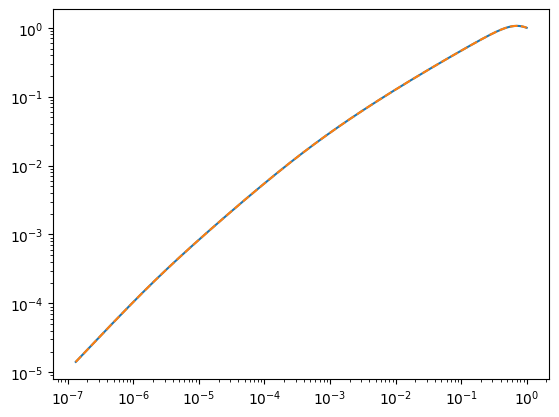

In [107]:
import matplotlib.pyplot as plt
plt.plot(asol, H_NORM*100/(asol*((a0* hsol)/asol**2)))
plt.plot(asol2, H_NORM*100/(asol2*((a02* hsol2)/asol2**2)), '--')
plt.xscale("log")
plt.yscale("log")

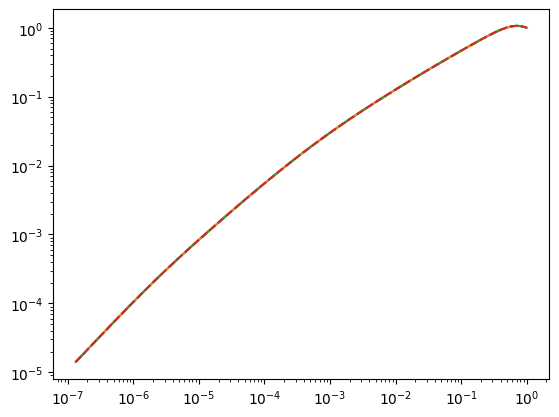

In [108]:
plt.plot(asol, H_NORM*100/(asol*(H_sol)))
plt.plot(asol, H_NORM*100/(asol*((a0* hsol)/asol**2)))
plt.plot(asol2, H_NORM*100/(asol2*(H_arr[::-1])), "-.")
plt.plot(asol2, H_NORM*100/(asol2*((a02* hsol2)/asol2**2)), '--')
plt.xscale("log")
plt.yscale("log")

In [109]:
def compute_desi_distances(asol, H_sol, rd):
    """
    Compute DESI DR2 BAO distances from the physical Hubble array.

    H_sol = a0 * hsol / a²  (physical Hubble in km/s/Mpc, from solve_stigma_jax).
    rd    should come from get_rd_camb for a theory-consistent sound horizon.

    DH(z)/rd = c / (H(z) * rd)
    DM(z)/rd = (c/rd) * ∫_{a(z)}^{1} da / (a² H(a))
    DV(z)/rd = (z * DM² * DH)^{1/3} / rd

    Returns
    -------
    theory : array shape (13,) matching desidr2_mean.txt row order
    """
    z_all = jnp.array([0.295, 0.510, 0.510, 0.706, 0.706,
                        0.934, 0.934, 1.321, 1.321, 1.484, 1.484, 2.330, 2.330])
    a_all = 1.0 / (1.0 + z_all)

    # ── DH(z)/rd = c / (H(z) * rd) ────────────────────────────────────────
    H_at_a     = jnp.interp(a_all, asol, H_sol)
    DH_over_rd = C_KMS / (H_at_a * rd)

    # ── DM(z)/rd = (c/rd) ∫_{a(z)}^{1} da/(a² H(a)) ──────────────────────
    integrand  = 1.0 / (asol**2 * H_sol)
    da_arr     = jnp.diff(asol)
    trap_terms = 0.5 * (integrand[:-1] + integrand[1:]) * da_arr
    cum_int    = jnp.concatenate([jnp.array([0.0]), jnp.cumsum(trap_terms)])

    cum_at_1   = jnp.interp(jnp.array(1.0), asol, cum_int)
    cum_at_az  = jnp.interp(a_all, asol, cum_int)
    DM_over_rd = C_KMS / rd * (cum_at_1 - cum_at_az)

    # ── DV(z)/rd ───────────────────────────────────────────────────────────
    DV_over_rd = (z_all * DM_over_rd**2 * DH_over_rd)**(1.0/3.0)

    theory = jnp.array([
        DV_over_rd[0],
        DM_over_rd[1],  DH_over_rd[2],
        DM_over_rd[3],  DH_over_rd[4],
        DM_over_rd[5],  DH_over_rd[6],
        DM_over_rd[7],  DH_over_rd[8],
        DM_over_rd[9],  DH_over_rd[10],
        DM_over_rd[11], DH_over_rd[12],
    ])
    return theory